# 06 · Đánh giá & so sánh tổng hợp

Đọc **mọi** file bản dịch trong `predictions/` và chấm điểm thống nhất trên tập test tst2013:

| Nhóm | Độ đo | Ý nghĩa |
|---|---|---|
| Dựa trên n-gram | **BLEU** (sacreBLEU), **chrF++**, **TER** | Trùng khớp từ/ký tự với bản dịch tham chiếu; TER = số thao tác sửa (càng thấp càng tốt) |
| Có so khớp mềm | **METEOR** | Có xét gốc từ/đồng nghĩa (WordNet chỉ có tiếng Anh ⇒ với tiếng Việt chủ yếu khớp chính xác) |
| Dựa trên mô hình | **BERTScore** (XLM-R large), **COMET** (wmt22-comet-da) | So khớp ngữ nghĩa bằng embedding; COMET được huấn luyện để bắt chước điểm của người đánh giá |
| Thống kê | **Paired bootstrap** (1000 mẫu) | Chênh lệch giữa 2 hệ thống có ý nghĩa thống kê không (p < 0,05) |
| Con người | **Adequacy / Fluency** (1–5) | File chấm điểm "mù" (không biết hệ thống nào) |

COMET/BERTScore chạy trong **môi trường Python riêng** (gói `unbabel-comet` xung đột phiên bản với Colab) —
lần đầu mất ~5 phút để cài.

> **Quy trình chống lỗi:** luôn chạy với `DRY_RUN = True` trước (vài phút, dữ liệu và mô hình tí hon, đi qua **mọi**
> dòng code). Khi không còn lỗi nào, đổi `DRY_RUN = False` rồi chọn **Runtime → Run all** để chạy thật.
> Kết quả chạy thử nằm riêng trong thư mục `dryrun/`, không lẫn với kết quả thật.

In [1]:
#@title ⚙️ Tham số
DRY_RUN = False
RUN_NEURAL = True            # COMET + BERTScore (cần GPU, lần đầu cài ~5 phút)
BASELINE = "tf_base_beam4"   # hệ thống làm mốc cho kiểm định bootstrap
HUMAN_EVAL_N = 100           # số câu cho phiếu đánh giá của người
HUMAN_EVAL_SYSTEMS = None    # None = tự chọn hệ thống tốt nhất của mỗi nhóm

In [2]:
#@title 🔧 Kết nối Google Drive + nạp thư viện `envi_lib`
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
PROJECT_DIR = os.environ.get("ENVI_PROJECT_DIR", "/content/drive/MyDrive/NLP_Final_EnVi")
if not os.path.exists(os.path.join(PROJECT_DIR, "envi_lib", "__init__.py")):
    raise FileNotFoundError(f"Chưa có thư viện ở {PROJECT_DIR}/envi_lib — hãy chạy notebook 00_cai_dat.ipynb trước.")
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
from envi_lib.common import (Paths, set_seed, get_device, pick_amp_dtype, autocast_ctx, gpu_info, peak_gpu_mem_gb,
                             reset_peak_mem, free_memory, count_params, disk_free_gb, save_predictions,
                             prediction_is_current, save_json, load_json, read_lines, write_lines, fmt_seconds,
                             bf16_supported, check_lib_version, now_str)
check_lib_version("1.0.0")
paths = Paths(PROJECT_DIR, dry_run=DRY_RUN).make_all()
DEVICE = get_device()
print(f"📁 {paths.root}   |   DRY_RUN = {DRY_RUN}   |   thiết bị: {gpu_info()}")

Mounted at /content/drive
📁 /content/drive/MyDrive/NLP_Final_EnVi   |   DRY_RUN = False   |   thiết bị: {'cuda': True, 'torch': '2.11.0+cu130', 'name': 'NVIDIA L4', 'total_gb': 22.0, 'bf16': True}


In [3]:
%pip install -q sacrebleu sacremoses sentencepiece
import re, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
from envi_lib import data as D, metrics as M
pd.set_option("display.max_colwidth", 100); pd.set_option("display.width", 200)
data = D.load_all_clean(paths, DRY_RUN)
test_src, test_ref = data["test"]
N = len(test_ref)

def classify(system):
    """(kiến trúc, cách huấn luyện, nhóm hiển thị)"""
    if system.startswith("tf_"):   return "Encoder-Decoder", "Train từ đầu", "Từ đầu · Enc-Dec"
    if system.startswith("gpt_"):  return "Decoder-only", "Train từ đầu", "Từ đầu · GPT"
    if system.startswith(("marian", "envit5", "nllb", "mt5")):
        return "Encoder-Decoder", "Pretrained", "Pretrained · Enc-Dec"
    return "Decoder-only (LLM)", "Pretrained", "Pretrained · LLM"

systems = {}
for f in sorted(paths.predictions.glob("*.vi.txt")):
    name = f.name.replace(".vi.txt", "")
    hyp = read_lines(f)
    if len(hyp) != N:
        print(f"⚠️  Bỏ qua {name}: {len(hyp)} dòng ≠ {N}"); continue
    systems[name] = hyp
assert systems, "Chưa có bản dịch nào — chạy các notebook 02–05 trước."
metas = {s: load_json(paths.predictions / f"{s}.meta.json") for s in systems}

# Hệ thống chính (bảng so sánh) vs. phân tích phụ (beam, ablation)
def is_main(s):
    if s.startswith(("tf_", "gpt_")):
        return s in ("tf_base_beam4", "gpt_base_beam4")
    return True
MAIN = [s for s in systems if is_main(s)]
print(f"{len(systems)} hệ thống | {len(MAIN)} hệ thống chính:", MAIN)

19 hệ thống | 11 hệ thống chính: ['envit5_ft', 'envit5_zeroshot', 'gpt_base_beam4', 'marian_ft', 'marian_zeroshot', 'mt5small_ft', 'nllb600m_zeroshot', 'qwen2.5-1.5b_5shot', 'qwen2.5-1.5b_lora', 'qwen2.5-1.5b_zeroshot', 'tf_base_beam4']


## 1. Độ đo dựa trên n-gram: BLEU · chrF++ · TER · METEOR

In [4]:
rows, sigs = [], {}
for s, hyp in systems.items():
    sc = M.corpus_scores(hyp, test_ref)
    met, met_seg = M.meteor(hyp, test_ref)
    arch, train_mode, group = classify(s)
    meta = metas[s]
    rows.append({"hệ thống": s, "nhóm": group, "kiến trúc": arch, "huấn luyện": meta.get("training", train_mode),
                 "BLEU": sc["BLEU"], "chrF++": sc["chrF++"], "TER↓": sc["TER"], "METEOR": met,
                 "BP": sc["BP"], "len_ratio": sc["len_ratio"], "p1/p2/p3/p4": f'{sc["p1"]}/{sc["p2"]}/{sc["p3"]}/{sc["p4"]}'})
    sigs = {k: v for k, v in sc.items() if k.startswith("_sig")}
lex = pd.DataFrame(rows).set_index("hệ thống")
save_json(sigs, paths.results / "sacrebleu_signatures.json")
print("Chữ ký sacreBLEU (ghi vào báo cáo để người khác tái lập):"); [print(" ", v) for v in sigs.values()]
lex.loc[MAIN].sort_values("BLEU", ascending=False)

Chữ ký sacreBLEU (ghi vào báo cáo để người khác tái lập):
  nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0
  nrefs:1|case:mixed|eff:yes|nc:6|nw:2|space:no|version:2.6.0
  nrefs:1|case:lc|tok:tercom|norm:no|punct:yes|asian:no|version:2.6.0


,nhóm,kiến trúc,huấn luyện,BLEU,chrF++,TER↓,METEOR,BP,len_ratio,p1/p2/p3/p4
hệ thống,,,,,,,,,,
marian_ft,Pretrained · Enc-Dec,Encoder-Decoder,Pretrained + fine-tune,37.50,55.55,48.92,60.32,1.000,1.009,67.9/44.8/30.6/21.2
marian_zeroshot,Pretrained · Enc-Dec,Encoder-Decoder,Pretrained (zero-shot),36.66,54.46,49.26,58.49,0.979,0.980,68.3/44.7/30.4/21.2
nllb600m_zeroshot,Pretrained · Enc-Dec,Encoder-Decoder,Pretrained (zero-shot),34.16,52.74,51.25,56.23,0.986,0.986,66.7/42.0/27.7/18.5
envit5_ft,Pretrained · Enc-Dec,Encoder-Decoder,Pretrained + fine-tune,33.65,51.78,53.03,55.44,0.999,0.999,64.8/40.8/26.9/18.1
tf_base_beam4,Từ đầu · Enc-Dec,Encoder-Decoder,Train từ đầu,31.41,50.06,55.16,53.81,0.994,0.994,63.7/38.7/24.8/16.3
qwen2.5-1.5b_lora,Pretrained · LLM,Decoder-only (LLM),Pretrained + LoRA fine-tune,31.35,50.80,54.68,55.18,0.996,0.996,64.6/38.9/24.6/15.9
gpt_base_beam4,Từ đầu · GPT,Decoder-only,Train từ đầu,30.00,48.83,56.16,52.10,0.974,0.975,63.3/38.1/24.0/15.5
mt5small_ft,Pretrained · Enc-Dec,Encoder-Decoder,Pretrained + fine-tune,26.65,45.48,60.11,48.11,0.985,0.985,59.3/34.1/20.6/12.9
qwen2.5-1.5b_zeroshot,Pretrained · LLM,Decoder-only (LLM),Pretrained (zero-shot),23.92,43.43,61.62,45.59,0.919,0.922,60.5/33.3/19.5/11.7


In [5]:
import os
os.environ["MPLBACKEND"] = "Agg"

## 2. Độ đo dựa trên mô hình: COMET · BERTScore (môi trường riêng)

In [6]:
neural = {}
neural_file = paths.results / "neural_scores.json"
if RUN_NEURAL:
    from envi_lib.neural_env import ensure_eval_env, run_neural_metrics
    try:
        py = ensure_eval_env("/content/eval_env" if IN_COLAB else str(paths.work / "eval_env"))
        tmp_src, tmp_ref = paths.results / "_test.en", paths.results / "_test.vi"
        write_lines(tmp_src, test_src); write_lines(tmp_ref, test_ref)
        run_neural_metrics(py, os.path.join(PROJECT_DIR, "envi_lib", "eval_neural.py"), tmp_src, tmp_ref,
                           [paths.predictions / f"{s}.vi.txt" for s in systems], neural_file,
                           batch=64 if DEVICE.type == "cuda" else 8)
    except Exception as e:
        # Không để lỗi COMET/BERTScore chặn các phần phân tích còn lại; kết quả từng hệ thống đã tính vẫn được giữ
        print(f"⚠️  Lỗi khi tính COMET/BERTScore — tiếp tục với các độ đo khác. Chi tiết:\n{e}")
if neural_file.exists():
    neural = load_json(neural_file)
neu = pd.DataFrame({s: {k: v for k, v in neural.get(s, {}).items() if k in ("COMET", "BERTScore_F1")} for s in systems}).T
table = lex.join(neu) if len(neu.columns) else lex
cols = ["nhóm", "huấn luyện", "BLEU", "chrF++", "TER↓", "METEOR"] + [c for c in ("BERTScore_F1", "COMET") if c in table]
main_table = table.loc[MAIN, cols].sort_values("COMET" if "COMET" in table else "BLEU", ascending=False)
main_table.to_csv(paths.results / "main_table.csv")
try:
    (paths.results / "main_table.md").write_text(main_table.to_markdown(), encoding="utf-8")
except ImportError:   # thiếu gói tabulate
    (paths.results / "main_table.md").write_text(main_table.to_string(), encoding="utf-8")
main_table

$ /usr/bin/python3 -m pip install -q uv
$ /usr/bin/python3 -m uv venv --clear /content/eval_env --python /usr/bin/python3
$ /usr/bin/python3 -m uv pip install --python /content/eval_env/bin/python torch==2.11.0 --index-url https://download.pytorch.org/whl/cu130
$ /usr/bin/python3 -m uv pip install --python /content/eval_env/bin/python unbabel-comet==2.2.7 bert-score==0.3.13 setuptools<81
$ /content/eval_env/bin/python -c import comet, bert_score, torch, transformers, numpy; print('OK torch', torch.__version__, 'cuda', torch.cuda.is_available(), 'transformers', transformers.__version__, 'numpy', numpy.__version__)
✔ Đã tạo môi trường đánh giá: /content/eval_env
$ /content/eval_env/bin/python /content/drive/MyDrive/NLP_Final_EnVi/envi_lib/eval_neural.py --src /content/drive/MyDrive/NLP_Final_EnVi/results/_test.en --ref /content/drive/MyDrive/NLP_Final_EnVi/results/_test.vi --out /content/drive/MyDrive/NLP_Final_EnVi/results/neural_scores.json --batch 64 --bertscore-model xlm-roberta-larg

,nhóm,huấn luyện,BLEU,chrF++,TER↓,METEOR,BERTScore_F1,COMET
hệ thống,,,,,,,,
marian_ft,Pretrained · Enc-Dec,Pretrained + fine-tune,37.50,55.55,48.92,60.32,95.42,86.86
qwen2.5-1.5b_lora,Pretrained · LLM,Pretrained + LoRA fine-tune,31.35,50.80,54.68,55.18,95.02,86.45
nllb600m_zeroshot,Pretrained · Enc-Dec,Pretrained (zero-shot),34.16,52.74,51.25,56.23,95.15,86.25
marian_zeroshot,Pretrained · Enc-Dec,Pretrained (zero-shot),36.66,54.46,49.26,58.49,95.31,86.19
envit5_ft,Pretrained · Enc-Dec,Pretrained + fine-tune,33.65,51.78,53.03,55.44,94.95,83.25
qwen2.5-1.5b_zeroshot,Pretrained · LLM,Pretrained (zero-shot),23.92,43.43,61.62,45.59,94.13,82.43
qwen2.5-1.5b_5shot,Pretrained · LLM,Pretrained (5-shot),23.62,43.36,61.91,45.06,94.15,81.98
tf_base_beam4,Từ đầu · Enc-Dec,Train từ đầu,31.41,50.06,55.16,53.81,94.64,80.85
gpt_base_beam4,Từ đầu · GPT,Train từ đầu,30.00,48.83,56.16,52.10,94.45,79.31


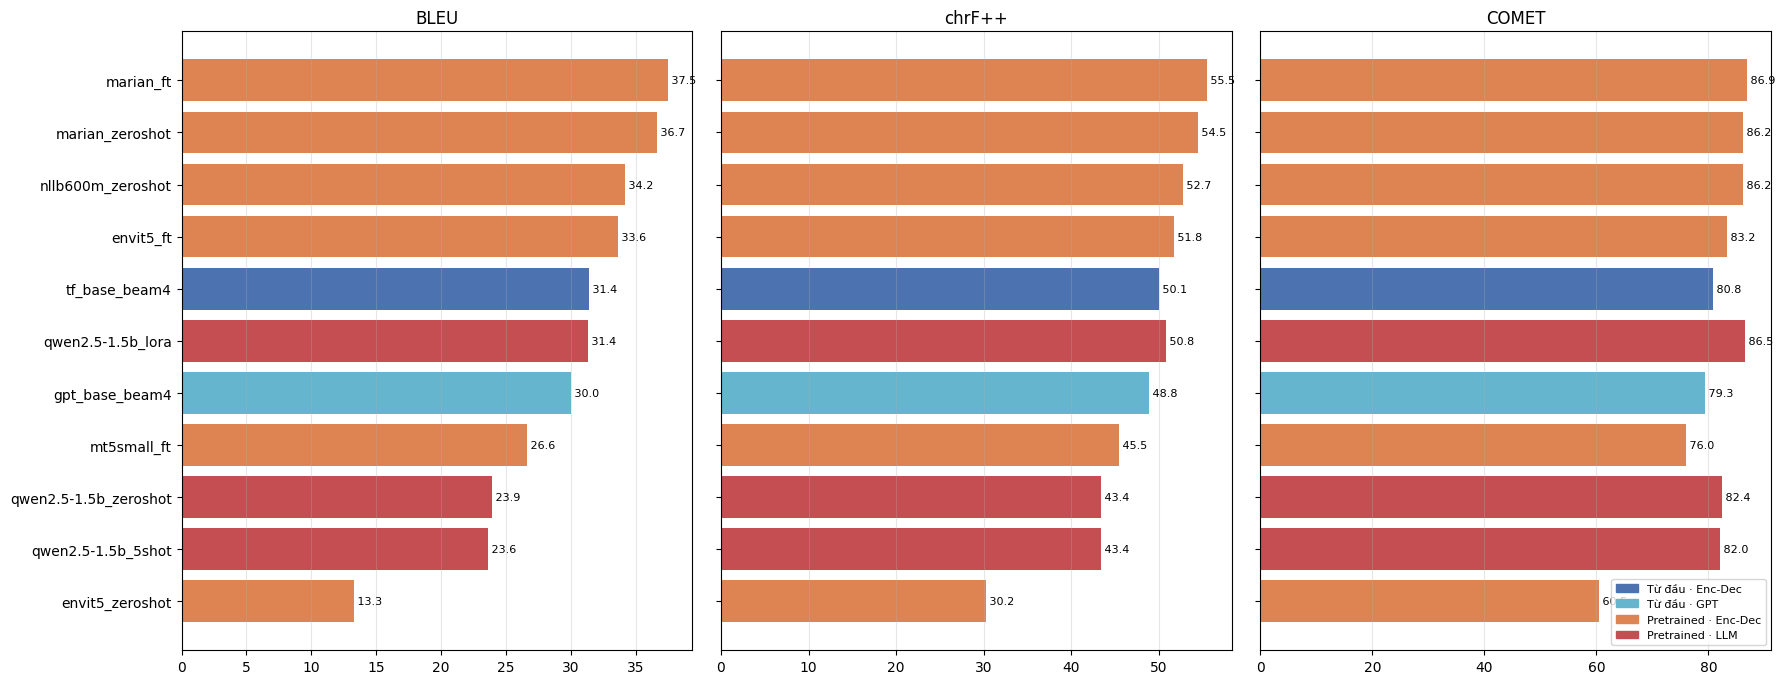

In [7]:
#@title 📊 Biểu đồ so sánh các hệ thống chính
metrics_plot = [c for c in ("BLEU", "chrF++", "COMET") if c in main_table]
fig, axes = plt.subplots(1, len(metrics_plot), figsize=(6 * len(metrics_plot), 0.45 * len(MAIN) + 2))
axes = np.atleast_1d(axes)
colors = {"Từ đầu · Enc-Dec": "#4C72B0", "Từ đầu · GPT": "#64B5CD", "Pretrained · Enc-Dec": "#DD8452", "Pretrained · LLM": "#C44E52"}
order = main_table.sort_values(metrics_plot[0]).index
for a, m in zip(axes, metrics_plot):
    vals = main_table.loc[order, m].astype(float)
    a.barh(range(len(order)), vals, color=[colors[main_table.loc[s, "nhóm"]] for s in order])
    a.set_yticks(range(len(order))); a.set_yticklabels(order if a is axes[0] else [])
    for i, v in enumerate(vals): a.text(v, i, f" {v:.1f}", va="center", fontsize=8)
    a.set_title(m); a.grid(axis="x", alpha=.3)
from matplotlib.patches import Patch
axes[-1].legend(handles=[Patch(color=c, label=g) for g, c in colors.items()], loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(paths.figures / "06_main_comparison.png", dpi=150); plt.show()

## 3. Kiểm định ý nghĩa thống kê (paired bootstrap resampling)

In [8]:
base = BASELINE if BASELINE in systems else MAIN[0]
st = {s: M.bleu_stats(systems[s], test_ref) for s in MAIN}
rows = []
for s in MAIN:
    if s == base: continue
    r = M.paired_bootstrap(st[base], st[s], n_samples=200 if DRY_RUN else 1000)
    row = {"hệ thống": s, "BLEU": r["sys_bleu"], "KTC 95%": r["sys_ci95"], f"Δ BLEU so với {base}": r["delta"],
           "p (BLEU)": r["p_value"]}
    if "COMET_seg" in neural.get(s, {}) and "COMET_seg" in neural.get(base, {}):
        c = M.paired_bootstrap_mean(neural[base]["COMET_seg"], neural[s]["COMET_seg"], n_samples=200 if DRY_RUN else 1000)
        row.update({"Δ COMET": round(100 * c["delta"], 2), "p (COMET)": c["p_value"]})
    rows.append(row)
sig = pd.DataFrame(rows).set_index("hệ thống")
sig.to_csv(paths.results / "significance.csv")
print(f"Mốc: {base} (BLEU {M.bleu_from_stats(st[base].sum(0)):.2f}). p < 0,05 ⇒ tốt hơn mốc có ý nghĩa thống kê; p > 0,95 ⇒ kém hơn có ý nghĩa.")
sig

Mốc: tf_base_beam4 (BLEU 31.41). p < 0,05 ⇒ tốt hơn mốc có ý nghĩa thống kê; p > 0,95 ⇒ kém hơn có ý nghĩa.


,BLEU,KTC 95%,Δ BLEU so với tf_base_beam4,p (BLEU),Δ COMET,p (COMET)
hệ thống,,,,,,
envit5_ft,33.65,"(32.7, 34.5)",2.20,0.000,2.41,0.0
envit5_zeroshot,13.27,"(12.63, 13.93)",-18.12,1.000,-20.33,1.0
gpt_base_beam4,30.00,"(29.11, 30.91)",-1.40,1.000,-1.54,1.0
marian_ft,37.50,"(36.55, 38.41)",6.10,0.000,6.01,0.0
marian_zeroshot,36.66,"(35.7, 37.58)",5.26,0.000,5.35,0.0
mt5small_ft,26.65,"(25.78, 27.51)",-4.75,1.000,-4.85,1.0
nllb600m_zeroshot,34.16,"(33.19, 35.05)",2.75,0.000,5.40,0.0
qwen2.5-1.5b_5shot,23.62,"(22.85, 24.46)",-7.79,1.000,1.14,0.0
qwen2.5-1.5b_lora,31.35,"(30.43, 32.2)",-0.08,0.592,5.61,0.0


## 4. Phân tích theo độ dài câu nguồn

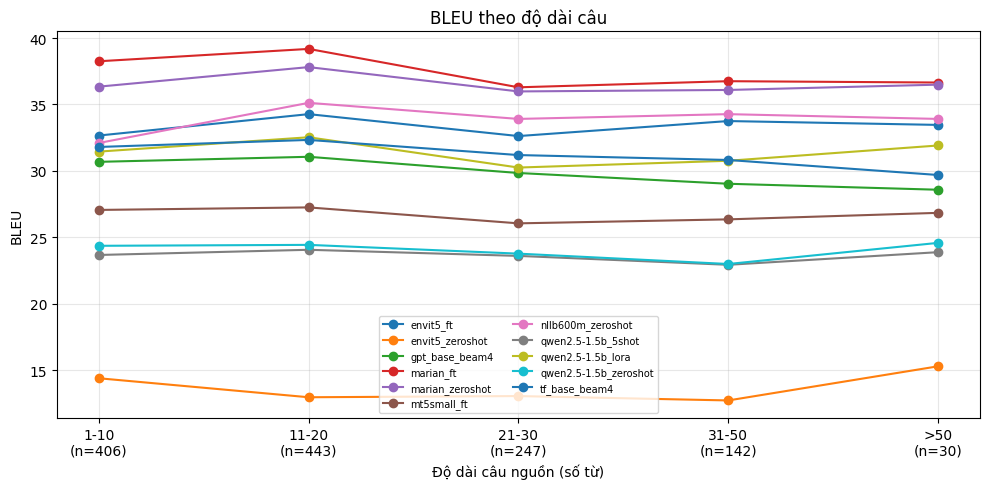

,1-10,11-20,21-30,31-50,>50
envit5_ft,32.66,34.27,32.62,33.75,33.46
envit5_zeroshot,14.39,12.96,13.05,12.72,15.29
gpt_base_beam4,30.68,31.06,29.84,29.03,28.58
marian_ft,38.25,39.18,36.29,36.75,36.65
marian_zeroshot,36.34,37.81,35.98,36.09,36.49
mt5small_ft,27.06,27.25,26.05,26.35,26.84
nllb600m_zeroshot,32.10,35.12,33.91,34.27,33.91
qwen2.5-1.5b_5shot,23.67,24.06,23.60,22.93,23.88
qwen2.5-1.5b_lora,31.45,32.53,30.25,30.76,31.91
qwen2.5-1.5b_zeroshot,24.36,24.43,23.77,22.99,24.58


In [9]:
bylen = {s: M.bleu_by_length(systems[s], test_ref, test_src) for s in MAIN}
bins = list(next(iter(bylen.values())).keys())
df_len = pd.DataFrame({s: {b: v[b]["BLEU"] for b in v} for s, v in bylen.items()}).T[bins]
counts = {b: next(iter(bylen.values()))[b]["n"] for b in bins}
plt.figure(figsize=(10, 5))
for s in df_len.index:
    plt.plot(range(len(bins)), df_len.loc[s], marker="o", label=s)
plt.xticks(range(len(bins)), [f"{b}\n(n={counts[b]})" for b in bins])
plt.xlabel("Độ dài câu nguồn (số từ)"); plt.ylabel("BLEU"); plt.grid(alpha=.3); plt.legend(fontsize=7, ncol=2)
plt.title("BLEU theo độ dài câu"); plt.tight_layout(); plt.savefig(paths.figures / "06_bleu_by_length.png", dpi=150); plt.show()
df_len.to_csv(paths.results / "bleu_by_length.csv"); df_len

## 5. Ảnh hưởng của beam size & các biến thể kiến trúc (ablation)

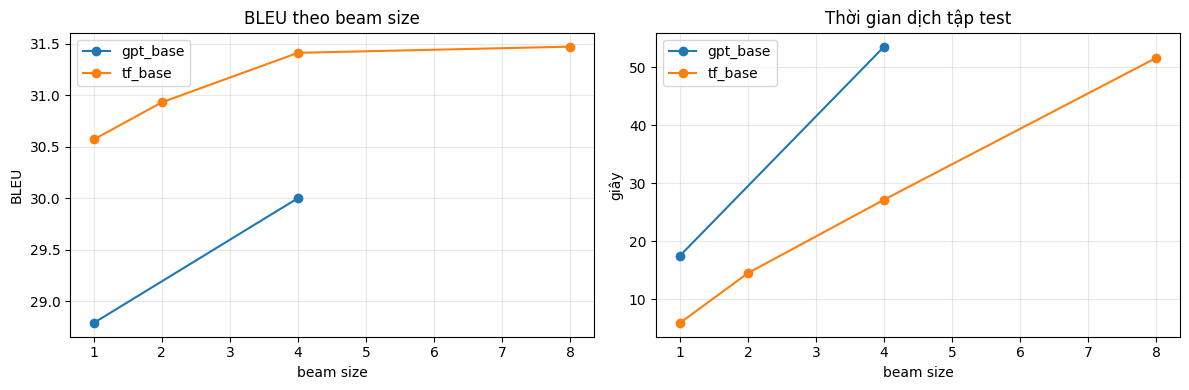

,mô hình,beam,BLEU,chrF++,thời gian dịch (s)
0,gpt_base,1,28.79,47.71,17.490607
1,gpt_base,4,30.00,48.83,53.576828
2,tf_base,1,30.57,49.43,5.874957
3,tf_base,2,30.93,49.75,14.487469
4,tf_base,4,31.41,50.06,27.150453
5,tf_base,8,31.47,50.11,51.630826


,BLEU,chrF++,TER↓,COMET,tham số (M),BLEU dev
hệ thống,,,,,,
gpt_base_beam4,30.00,48.83,56.16,79.31,40.0,29.49
gpt_sinusoidal_beam4,30.49,49.25,56.08,79.50,39.7,29.93
tf_3layers_beam4,30.46,49.31,55.47,79.80,24.0,30.44
tf_base_beam4,31.41,50.06,55.16,80.85,39.7,31.04
tf_learned_pos_beam4,29.74,48.88,56.93,79.58,40.0,29.53
tf_postnorm_beam4,6.39,23.68,89.23,59.49,39.7,6.16


In [10]:
beam_rows = []
for s in systems:
    m = re.match(r"^(tf_base|gpt_base)_beam(\d+)$", s)
    if m:
        beam_rows.append({"mô hình": m.group(1), "beam": int(m.group(2)), "BLEU": lex.loc[s, "BLEU"],
                          "chrF++": lex.loc[s, "chrF++"], "thời gian dịch (s)": metas[s].get("decode_time_s")})
beam_df = pd.DataFrame(beam_rows).sort_values(["mô hình", "beam"]) if beam_rows else pd.DataFrame()
if len(beam_df):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for mname, g in beam_df.groupby("mô hình"):
        ax[0].plot(g["beam"], g["BLEU"], marker="o", label=mname); ax[1].plot(g["beam"], g["thời gian dịch (s)"], marker="o", label=mname)
    ax[0].set(xlabel="beam size", ylabel="BLEU", title="BLEU theo beam size"); ax[1].set(xlabel="beam size", ylabel="giây", title="Thời gian dịch tập test")
    for a in ax: a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(paths.figures / "06_beam_size.png", dpi=150); plt.show()
abl = [s for s in systems if re.match(r"^(tf|gpt)_.*_beam4$", s)]
abl_df = table.loc[abl, [c for c in ("BLEU", "chrF++", "TER↓", "COMET") if c in table]].copy()
abl_df["tham số (M)"] = [round(metas[s]["params"] / 1e6, 1) for s in abl]
abl_df["BLEU dev"] = [round(metas[s].get("best_dev_bleu", float("nan")), 2) for s in abl]
abl_df.to_csv(paths.results / "ablation.csv"); beam_df.to_csv(paths.results / "beam_size.csv", index=False)
display(beam_df) if len(beam_df) else None
abl_df

## 6. Chi phí: tham số, thời gian huấn luyện, thời gian dịch, bộ nhớ

In [11]:
def trainable(m):
    if "trainable_params" in m:
        return m["trainable_params"]
    t = m.get("training", "")
    return m.get("params", 0) if ("từ đầu" in t or "fine-tune" in t) else 0

cost = pd.DataFrame([{
    "hệ thống": s, "tham số (M)": round(metas[s].get("params", 0) / 1e6, 1),
    "tham số huấn luyện (M)": round(trainable(metas[s]) / 1e6, 1),
    "thời gian train": fmt_seconds(metas[s]["train_time_s"]) if metas[s].get("train_time_s") else "—",
    "dịch 1 câu (ms)": round(1000 * metas[s].get("decode_time_s", float("nan")) / N, 1),
    "VRAM đỉnh khi dịch (GB)": metas[s].get("peak_mem_gb"), "GPU": metas[s].get("gpu")} for s in MAIN]).set_index("hệ thống")
cost.to_csv(paths.results / "cost.csv"); cost

,tham số (M),tham số huấn luyện (M),thời gian train,dịch 1 câu (ms),VRAM đỉnh khi dịch (GB),GPU
hệ thống,,,,,,
envit5_ft,275.1,275.1,14m36s,52.8,3.56,NVIDIA A100-SXM4-80GB
envit5_zeroshot,275.1,0.0,—,40.0,3.12,NVIDIA A100-SXM4-80GB
gpt_base_beam4,40.0,40.0,1h30m36s,42.3,1.68,NVIDIA L4
marian_ft,72.1,72.1,5m29s,13.5,0.91,NVIDIA A100-SXM4-80GB
marian_zeroshot,72.1,0.0,—,13.0,0.91,NVIDIA A100-SXM4-80GB
mt5small_ft,300.2,300.2,47m28s,43.8,2.41,NVIDIA A100-SXM4-80GB
nllb600m_zeroshot,615.1,0.0,—,23.4,5.44,NVIDIA A100-SXM4-80GB
qwen2.5-1.5b_5shot,1543.7,0.0,—,118.9,3.51,NVIDIA L4
qwen2.5-1.5b_lora,1543.7,18.5,1h32m40s,57.2,3.30,NVIDIA L4


## 7. Tương quan giữa các độ đo (phục vụ phần "phương pháp đánh giá")

In [12]:
num = table.loc[MAIN, [c for c in ("BLEU", "chrF++", "TER↓", "METEOR", "BERTScore_F1", "COMET") if c in table]].astype(float)
if len(num) >= 3:
    from scipy.stats import kendalltau
    corr_p = num.corr(method="pearson").round(3)
    corr_k = pd.DataFrame({a: {b: round(kendalltau(num[a], num[b])[0], 3) for b in num} for a in num})
    corr_p.to_csv(paths.results / "metric_corr_pearson.csv"); corr_k.to_csv(paths.results / "metric_corr_kendall.csv")
    print("Lưu ý: TER càng THẤP càng tốt ⇒ tương quan với các độ đo khác mang dấu ÂM là bình thường.")
    print("Tương quan Pearson giữa các độ đo (mức hệ thống):"); display(corr_p)
    print("Kendall tau (mức hệ thống — thứ hạng có nhất quán không):"); display(corr_k)
else:
    print("Cần ≥ 3 hệ thống để tính tương quan.")

Lưu ý: TER càng THẤP càng tốt ⇒ tương quan với các độ đo khác mang dấu ÂM là bình thường.
Tương quan Pearson giữa các độ đo (mức hệ thống):


,BLEU,chrF++,TER↓,METEOR,BERTScore_F1,COMET
BLEU,1.000,0.993,-0.991,0.988,0.965,0.859
chrF++,0.993,1.000,-0.998,0.999,0.987,0.903
TER↓,-0.991,-0.998,1.000,-0.996,-0.988,-0.911
METEOR,0.988,0.999,-0.996,1.000,0.988,0.909
BERTScore_F1,0.965,0.987,-0.988,0.988,1.000,0.959
COMET,0.859,0.903,-0.911,0.909,0.959,1.000


Kendall tau (mức hệ thống — thứ hạng có nhất quán không):


,BLEU,chrF++,TER↓,METEOR,BERTScore_F1,COMET
BLEU,1.000,0.964,-0.964,0.964,0.818,0.600
chrF++,0.964,1.000,-1.000,1.000,0.855,0.636
TER↓,-0.964,-1.000,1.000,-1.000,-0.855,-0.636
METEOR,0.964,1.000,-1.000,1.000,0.855,0.636
BERTScore_F1,0.818,0.855,-0.855,0.855,1.000,0.709
COMET,0.600,0.636,-0.636,0.636,0.709,1.000


## 8. Ví dụ bản dịch (phân tích định tính)

In [13]:
rng = random.Random(7)
cand = [i for i, s in enumerate(test_src) if 8 <= len(s.split()) <= 25]
ex_ids = rng.sample(cand, min(8, len(cand)))
lines = []
for i in ex_ids:
    lines.append(f"### Câu {i}\n- **Nguồn (EN):** {test_src[i]}\n- **Tham chiếu:** {test_ref[i]}")
    for s in MAIN:
        lines.append(f"- `{s}`: {systems[s][i]}")
    lines.append("")
(paths.results / "examples.md").write_text("\n".join(lines), encoding="utf-8")
from IPython.display import Markdown, display
display(Markdown("\n".join(lines[: 6 * (len(MAIN) + 3)])))

### Câu 535
- **Nguồn (EN):** Women won 17.5 percent of the National Congress in the first elections ever in 52 years.
- **Tham chiếu:** Phụ nữ thắng 17,5 phần trăm trong Quốc Hội Nhà Nước ở những cuộc bầu cử đầu tiên trong vòng 52 năm trở lại đây.
- `envit5_ft`: Phụ nữ đã giành được 17.5% của Quốc hội trong các cuộc bầu cử đầu tiên trong 52 năm.
- `envit5_zeroshot`: Phụ nữ sống 17,5 năm ở National Congress trong 52 năm.
- `gpt_base_beam4`: Phụ nữ đã thắng 17.5 phần trăm của Quốc hội trong cuộc bầu cử đầu tiên trong 52 năm.
- `marian_ft`: Phụ nữ thắng 17.5 phần trăm của Quốc hội trong cuộc bầu cử đầu tiên trong 52 năm qua.
- `marian_zeroshot`: Phụ nữ thắng 17.5 phần trăm Quốc hội trong cuộc bầu cử đầu tiên trong 52 năm qua.
- `mt5small_ft`: Phụ nữ đã chiến thắng 25% của Quốc hội Quốc hội trong cuộc bầu cử đầu tiên trong 52 năm.
- `nllb600m_zeroshot`: Phụ nữ giành được 17,5 phần trăm của Quốc hội trong cuộc bầu cử đầu tiên trong 52 năm.
- `qwen2.5-1.5b_5shot`: Người phụ nữ giành được 17,5% trong Quốc hội lần đầu tiên sau 52 năm.
- `qwen2.5-1.5b_lora`: Phụ nữ đã giành được 17.5% số ghế Quốc hội trong cuộc bầu cử đầu tiên vào năm 52 năm trước.
- `qwen2.5-1.5b_zeroshot`: Ngày đầu tiên, phụ nữ giành được 17,5% số ghế trong Quốc hội quốc gia, một lần đầu tiên trong 52 năm.
- `tf_base_beam4`: Phụ nữ đã giành được 17.5% quốc hội quốc gia trong các cuộc bầu cử đầu tiên trong 52 năm.

### Câu 259
- **Nguồn (EN):** I realized that the man who I loved so much was going to kill me if I let him.
- **Tham chiếu:** Tôi nhận ra rằng người đàn ông tôi rất yêu thương sẽ giết tôi nếu tôi bỏ rơi anh ta.
- `envit5_ft`: Tôi nhận ra rằng người đàn ông mà tôi yêu thương rất nhiều sẽ giết tôi nếu tôi để ông ấy làm thế.
- `envit5_zeroshot`: Tôi đã nói với người đàn ông mà tôi đã yêu vì vậy much whets will going to kill me if I let him.
- `gpt_base_beam4`: Tôi nhận ra rằng người đàn ông mà tôi yêu thích nhất sẽ giết tôi nếu tôi để ông ấy.
- `marian_ft`: Tôi nhận ra rằng người đàn ông mà tôi yêu quý sẽ giết tôi nếu tôi cho phép.
- `marian_zeroshot`: Tôi nhận ra rằng người đàn ông tôi yêu thương sẽ giết tôi nếu tôi để anh ta làm thế.
- `mt5small_ft`: Tôi nhận ra rằng người đàn ông tôi yêu rất nhiều sẽ giết tôi nếu tôi để anh ta.
- `nllb600m_zeroshot`: Tôi nhận ra rằng người đàn ông mà tôi yêu thương rất nhiều sẽ giết tôi nếu tôi cho phép anh ta.
- `qwen2.5-1.5b_5shot`: Tôi nhận ra rằng người đàn ông mà tôi yêu thương sâu sắc sẽ giết tôi nếu tôi cho phép anh ta.
- `qwen2.5-1.5b_lora`: Tôi nhận ra rằng người đàn ông mà tôi yêu thương rất nhiều sẽ giết chết tôi nếu tôi để cho anh ta làm vậy.
- `qwen2.5-1.5b_zeroshot`: Tôi nhận ra rằng người tôi yêu thương sâu sắc sẽ giết tôi nếu tôi cho phép anh ta.
- `tf_base_beam4`: Tôi nhận ra rằng người đàn ông mà tôi rất thích sẽ giết tôi nếu tôi để cho anh ấy.

### Câu 654
- **Nguồn (EN):** Here's me at a slumber party a few days before I shot French Vogue.
- **Tham chiếu:** Đây là tôi ở tiệc ngủ vài ngày trước khi chụp ảnh cho Vogue Pháp.
- `envit5_ft`: Đây là tôi tại một bữa tiệc khu ổ chuột vài ngày trước khi tôi bắn French Vogue.
- `envit5_zeroshot`: Tôi đang ở một khu ổ chuột trước khi tôi làm phiền French Vogue.
- `gpt_base_beam4`: Đây là tôi ở một bữa tiệc dưa leo vài ngày trước khi tôi quay Pháp Vogue.
- `marian_ft`: Đây là tôi tại một bữa tiệc ngủ vài ngày trước khi tôi bắn Vogue Pháp.
- `marian_zeroshot`: Đây là tôi ở bữa tiệc ngủ vài ngày trước khi tôi bắn Vogue Pháp.
- `mt5small_ft`: Đây là tôi tại một buổi tiệc gỗ vài ngày trước khi tôi chụp Vogue Pháp.
- `nllb600m_zeroshot`: Đây là tôi ở một bữa tiệc ngủ một vài ngày trước khi chụp ảnh Vogue Pháp.
- `qwen2.5-1.5b_5shot`: Hôm nay, tôi ở một bữa tiệc say ngủ vài ngày trước khi tôi chụp ảnh cho Vogue Pháp.
- `qwen2.5-1.5b_lora`: Đây là tôi trong một buổi tiệc ngủ ngon vài ngày trước khi tôi chụp ảnh cho tạp chí Pháp Vogue.
- `qwen2.5-1.5b_zeroshot`: Đây là tôi ở một bữa tiệc say sưa vài ngày trước khi tôi chụp ảnh cho Vogue Pháp.
- `tf_base_beam4`: Đây là tôi ở một bữa tiệc ngủ ngon vài ngày trước khi tôi chụp Pháp Vogue.

### Câu 1113
- **Nguồn (EN):** It's very easy to do more damage to those damaged photos.
- **Tham chiếu:** Rất dễ gây thêm hư hại cho những hình ảnh đã hư hại này.
- `envit5_ft`: Rất dễ dàng để làm tổn thương nhiều hơn cho những bức ảnh bị tổn thương.
- `envit5_zeroshot`: Thật dễ chịu khi làm tổn thương những người bị tổn thương.
- `gpt_base_beam4`: Rất dễ gây tổn thương cho những bức ảnh bị tổn thương này.
- `marian_ft`: Rất dễ để gây nhiều thiệt hại hơn cho những bức ảnh bị tổn thương này.
- `marian_zeroshot`: Rất dễ gây tổn thương cho những bức ảnh bị hư hại đó.
- `mt5small_ft`: Nó rất dễ dàng để làm nhiều tổn thương hơn với những bức ảnh bị tổn thương.
- `nllb600m_zeroshot`: Thật dễ dàng để làm thêm thiệt hại cho những bức ảnh bị hư hỏng đó.
- `qwen2.5-1.5b_5shot`: Rất dễ làm tổn thương thêm cho những bức ảnh bị hỏng.
- `qwen2.5-1.5b_lora`: Thực sự rất dễ làm tổn hại thêm cho những bức ảnh bị hư hỏng.
- `qwen2.5-1.5b_zeroshot`: Đánh giá ảnh đã bị tổn thương rất dễ gây ra nhiều tổn hại hơn.
- `tf_base_beam4`: Rất dễ để gây ra thiệt hại cho những bức ảnh bị tổn thương này.

### Câu 65
- **Nguồn (EN):** Since my family couldn't understand Chinese, I thought my family was going to be arrested.
- **Tham chiếu:** Bởi vì gia đình tôi không hiểu tiếng Trung, nên tôi đã nghĩ rằng họ sẽ bị bắt.
- `envit5_ft`: Vì gia đình tôi không thể hiểu được tiếng Trung, tôi nghĩ gia đình tôi sẽ bị bắt.
- `envit5_zeroshot`: Since family của tôi không thể understand Chinese, tôi khó chịu family was going arrested.
- `gpt_base_beam4`: Vì gia đình tôi không thể hiểu tiếng Trung, tôi nghĩ gia đình tôi sẽ bị bắt.
- `marian_ft`: Vì gia đình tôi không hiểu tiếng Trung Quốc, nên tôi nghĩ gia đình tôi sẽ bị bắt.
- `marian_zeroshot`: Vì gia đình tôi không hiểu tiếng Trung Quốc, nên tôi nghĩ gia đình tôi sẽ bị bắt.
- `mt5small_ft`: Bởi vì gia đình tôi không thể hiểu Trung Quốc, tôi nghĩ gia đình tôi sẽ bị bắt.
- `nllb600m_zeroshot`: Vì gia đình tôi không hiểu tiếng Trung Quốc, tôi nghĩ họ sẽ bị bắt.
- `qwen2.5-1.5b_5shot`: Dù gia đình tôi không hiểu tiếng Trung, tôi nghĩ rằng gia đình tôi sẽ bị bắt.
- `qwen2.5-1.5b_lora`: Vì gia đình tôi không thể hiểu tiếng Trung Quốc, tôi nghĩ rằng họ sẽ bị bắt.
- `qwen2.5-1.5b_zeroshot`: Dù gia đình tôi không hiểu tiếng Trung nhưng tôi nghĩ rằng gia đình tôi sẽ bị bắt.
- `tf_base_beam4`: Vì gia đình tôi không thể hiểu tiếng Trung Quốc, tôi nghĩ gia đình mình sẽ bị bắt.

### Câu 120
- **Nguồn (EN):** Now, I cannot deny that there have been some challenging moments in my family, moments where I've wished that they were just like me.
- **Tham chiếu:** Chà, tôi không thể phủ nhận rằng đã có một vài khoảnh khắc khó khăn trong gia đình tôi, những khoảnh khắc tôi ước ao các em cũng giống như mình.
- `envit5_ft`: Bây giờ, tôi không thể phủ nhận rằng đã có những khoảnh khắc khó khăn trong gia đình tôi, những khoảnh khắc mà tôi ước rằng họ cũng giống như tôi.
- `envit5_zeroshot`: Bây giờ, tôi không thể làm cho bạn khóc there có được một số challenging khóc trong sự nam tính của tôi, khóc những gì tôi đã wished that họ đang chỉ giống như tôi.
- `gpt_base_beam4`: Bây giờ, tôi không thể phủ nhận rằng đã có một vài khoảnh khắc thách thức trong gia đình, những khoảnh khắc mà tôi ước rằng họ giống như tôi.
- `marian_ft`: Bây giờ, tôi không thể phủ nhận rằng đã có những khoảnh khắc khó khăn trong gia đình tôi, những khoảnh khắc mà tôi ước rằng chúng cũng giống như tôi.
- `marian_zeroshot`: Bây giờ, tôi không thể phủ nhận rằng có một số khoảnh khắc khó khăn trong gia đình tôi, những khoảnh khắc mà tôi đã ước rằng chúng cũng giống như tôi.
- `mt5small_ft`: Bây giờ, tôi không thể bảo rằng có một vài khoảnh khắc khó khăn trong gia đình tôi, khoảnh khắc mà tôi mong rằng chúng giống như tôi.
- `nllb600m_zeroshot`: Bây giờ, tôi không thể phủ nhận rằng đã có một số khoảnh khắc khó khăn trong gia đình tôi, khoảnh khắc mà tôi ước rằng họ cũng giống như tôi.
- `qwen2.5-1.5b_5shot`: Vậy, tôi không thể phủ nhận rằng trong gia đình mình đã có những thời điểm khó khăn, những lúc tôi mong muốn họ giống như tôi.
- `qwen2.5-1.5b_lora`: Tôi không thể từ chối rằng có những thời điểm khó khăn trong gia đình tôi, những lúc mà tôi mong muốn họ giống như mình.
- `qwen2.5-1.5b_zeroshot`: Đây là một tình huống khó khăn trong gia đình tôi, những lúc tôi mong rằng họ giống như tôi.
- `tf_base_beam4`: Bây giờ, tôi không thể phủ nhận rằng đã có những khoảnh khắc khó khăn trong gia đình tôi, những khoảnh khắc mà tôi ước rằng họ giống như tôi.

### Câu 912
- **Nguồn (EN):** And the indicator box makes the lights flash.
- **Tham chiếu:** Và chiếc hộp đồng hồ đo làm cho đèn chớp tắt.
- `envit5_ft`: Và chiếc hộp chỉ thị làm cho ánh sáng lên.
- `envit5_zeroshot`: Và những tia sáng lóe lên.
- `gpt_base_beam4`: Và cái hộp này tạo ra ánh sáng.
- `marian_ft`: Và cái hộp chỉ số làm cho ánh sáng nhấp nháy.
- `marian_zeroshot`: Và cái hộp chỉ số làm cho ánh sáng nhấp nháy.

## 9. Đánh giá của con người (blind)
1. Ô dưới tạo file `results/human_eval_sheet.csv`: mỗi dòng là (câu nguồn, tham chiếu, một bản dịch) đã **xáo trộn và
   ẩn tên hệ thống**. Mở bằng Google Sheets, chấm 2 cột:
   - **adequacy** (1–5): bản dịch truyền tải đủ ý nghĩa câu nguồn đến đâu.
   - **fluency** (1–5): câu tiếng Việt tự nhiên, đúng ngữ pháp đến đâu.
2. Tải về dạng CSV, đặt tên `human_eval_filled.csv` vào cùng thư mục `results/`, rồi chạy ô tổng hợp.

In [14]:
#@title 📝 Tạo phiếu chấm điểm (chỉ tạo MỘT lần — không ghi đè phiếu đã có để không lệch với khoá giải mã)
REGENERATE_SHEET = False
sheet_file, key_file = paths.results / "human_eval_sheet.csv", paths.results / "human_eval_key.json"
if sheet_file.exists() and key_file.exists() and not REGENERATE_SHEET:
    print(f"✔ Đã có phiếu: {sheet_file} (đặt REGENERATE_SHEET=True nếu muốn tạo lại)")
else:
  sel = HUMAN_EVAL_SYSTEMS
  if not sel:   # hệ thống có BLEU cao nhất trong mỗi nhóm
      sel = list(table.loc[MAIN].sort_values("BLEU", ascending=False).groupby("nhóm").head(1).index)
  rng = random.Random(2026)
  ids = rng.sample(range(N), min(HUMAN_EVAL_N, N))
  codes = {s: chr(65 + i) for i, s in enumerate(sel)}
  rows = [{"item": f"{i}-{codes[s]}", "sent_id": i, "src_en": test_src[i], "ref_vi": test_ref[i], "hyp_vi": systems[s][i],
           "adequacy": "", "fluency": ""} for i in ids for s in sel]
  rng.shuffle(rows)
  sheet = pd.DataFrame(rows)
  sheet.to_csv(sheet_file, index=False, encoding="utf-8-sig")
  save_json(codes, key_file)   # khoá giải mã — không mở khi đang chấm
  print(f"✔ {len(sheet)} dòng ({len(ids)} câu × {len(sel)} hệ thống): {sheet_file}")

✔ Đã có phiếu: /content/drive/MyDrive/NLP_Final_EnVi/results/human_eval_sheet.csv (đặt REGENERATE_SHEET=True nếu muốn tạo lại)


In [15]:
#@title 📊 Tổng hợp điểm của người (chạy sau khi đã chấm)
filled = paths.results / "human_eval_filled.csv"
if filled.exists():
    h = pd.read_csv(filled, keep_default_na=False, na_values={"adequacy": [""], "fluency": [""]})
    for c in ("src_en", "ref_vi", "hyp_vi"):
        h[c] = h[c].astype(str)
    key = {v: k for k, v in load_json(paths.results / "human_eval_key.json").items()}
    h["hệ thống"] = h["item"].str.split("-").str[-1].map(key)
    h = h.dropna(subset=["adequacy", "fluency"])
    hum = h.groupby("hệ thống")[["adequacy", "fluency"]].agg(["mean", "std", "count"]).round(2)
    hum.to_csv(paths.results / "human_eval_summary.csv")
    display(hum)
    # tương quan mức câu giữa điểm người và độ đo tự động
    from sacrebleu.metrics import CHRF
    chrf = CHRF(word_order=2)
    h["chrF++_câu"] = [chrf.sentence_score(r.hyp_vi, [r.ref_vi]).score for r in h.itertuples()]
    if neural:
        h["COMET_câu"] = [neural.get(s, {}).get("COMET_seg", [np.nan] * N)[i] for s, i in zip(h["hệ thống"], h["sent_id"])]
    print("Tương quan Kendall giữa điểm người và độ đo tự động (mức câu):")
    display(h[["adequacy", "fluency"] + [c for c in ("chrF++_câu", "COMET_câu") if c in h]].corr(method="kendall").round(3))
else:
    print("Chưa có human_eval_filled.csv — bỏ qua.")

Chưa có human_eval_filled.csv — bỏ qua.


In [16]:
#@title 💾 Xuất toàn bộ bảng kết quả
with pd.ExcelWriter(paths.results / "ket_qua_tong_hop.xlsx") as w:
    table.to_excel(w, sheet_name="tat_ca_he_thong")
    main_table.to_excel(w, sheet_name="bang_chinh")
    sig.to_excel(w, sheet_name="kiem_dinh")
    df_len.to_excel(w, sheet_name="theo_do_dai")
    abl_df.to_excel(w, sheet_name="ablation")
    if len(beam_df): beam_df.to_excel(w, sheet_name="beam_size", index=False)
    cost.to_excel(w, sheet_name="chi_phi")
print("✔ Đã lưu:", paths.results / "ket_qua_tong_hop.xlsx")
print("Hình vẽ:", sorted(p.name for p in paths.figures.glob("*.png")))

✔ Đã lưu: /content/drive/MyDrive/NLP_Final_EnVi/results/ket_qua_tong_hop.xlsx
Hình vẽ: ['02_cross_attention.png', '02_learning_curves.png', '03_gpt_attention.png', '03_learning_curves.png', '06_beam_size.png', '06_bleu_by_length.png', '06_main_comparison.png', 'eda_lengths.png']
